In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/home/jovyan/bd-a1/data/dataset.csv")
df.head()

,COMMENT_ID,AUTHOR,DATE,CONTENT,CLASS,SOURCE_VIDEO
0,LZQPQhLyRh80UYxNuaDWhIGQYNQ96IuCg-AYWqNPjpU,Julius NM,2013-11-07T06:20:48,"Huh, anyway check out this you[tube] channel: ...",1,Youtube01-Psy
1,LZQPQhLyRh_C2cTtd9MvFRJedxydaVW-2sNg5Diuo4A,adam riyati,2013-11-07T12:37:15,Hey guys check out my new channel and our firs...,1,Youtube01-Psy
2,LZQPQhLyRh9MSZYnf8djyk0gEF9BHDPYrrK-qCczIY8,Evgeny Murashkin,2013-11-08T17:34:21,just for test I have to say murdev.com,1,Youtube01-Psy
3,z13jhp0bxqncu512g22wvzkasxmvvzjaz04,ElNino Melendez,2013-11-09T08:28:43,me shaking my sexy ass on my channel enjoy ^_^ ﻿,1,Youtube01-Psy
4,z13fwbwp1oujthgqj04chlngpvzmtt3r3dw,GsMega,2013-11-10T16:05:38,watch?v=vtaRGgvGtWQ Check this out .﻿,1,Youtube01-Psy


In [3]:
print("Dataset shape:", df.shape)

print("\ncolumn names:")
print(df.columns.tolist())

print("\nData types and missing values:")
df.info()

print("\nStatistical summary:")
df.describe(include="all")

Dataset shape: (1956, 6)

column names:
['COMMENT_ID', 'AUTHOR', 'DATE', 'CONTENT', 'CLASS', 'SOURCE_VIDEO']

Data types and missing values:
<class 'pandas.DataFrame'>
RangeIndex: 1956 entries, 0 to 1955
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   COMMENT_ID    1956 non-null   str  
 1   AUTHOR        1956 non-null   str  
 2   DATE          1711 non-null   str  
 3   CONTENT       1956 non-null   str  
 4   CLASS         1956 non-null   int64
 5   SOURCE_VIDEO  1956 non-null   str  
dtypes: int64(1), str(5)
memory usage: 443.7 KB

Statistical summary:


,COMMENT_ID,AUTHOR,DATE,CONTENT,CLASS,SOURCE_VIDEO
count,1956,1956,1711,1956,1956.000000,1956
unique,1953,1792,1709,1760,NaN,5
top,LneaDw26bFvPh9xBHNw1btQoyP60ay_WWthtvXCx37s,M.E.S,2014-11-07T19:33:46,Check out this video on YouTube:﻿,NaN,Youtube04-Eminem
freq,2,8,2,97,NaN,448
mean,NaN,NaN,NaN,NaN,0.513804,NaN
std,NaN,NaN,NaN,NaN,0.499937,NaN
min,NaN,NaN,NaN,NaN,0.000000,NaN
25%,NaN,NaN,NaN,NaN,0.000000,NaN
50%,NaN,NaN,NaN,NaN,1.000000,NaN
75%,NaN,NaN,NaN,NaN,1.000000,NaN


In [4]:
print("Missing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

print("Duplicate comment IDs:", df["COMMENT_ID"].duplicated().sum())

print("\nClass distribution:")
print(df["CLASS"].value_counts())
duplicates = df[df.duplicated(keep=False)]
duplicates.sort_values("COMMENT_ID")

Missing values:
COMMENT_ID        0
AUTHOR            0
DATE            245
CONTENT           0
CLASS             0
SOURCE_VIDEO      0
dtype: int64

Duplicate rows: 3
Duplicate comment IDs: 3

Class distribution:
CLASS
1    1005
0     951
Name: count, dtype: int64


,COMMENT_ID,AUTHOR,DATE,CONTENT,CLASS,SOURCE_VIDEO
1441,LneaDw26bFuH6iFsSrjlJLJIX3qD4R8-emuZ-aGUj0o,Amir bassem,NaN,if u love rihanna subscribe me,1,Youtube04-Eminem
1443,LneaDw26bFuH6iFsSrjlJLJIX3qD4R8-emuZ-aGUj0o,Amir bassem,NaN,if u love rihanna subscribe me,1,Youtube04-Eminem
1420,LneaDw26bFvPh9xBHNw1btQoyP60ay_WWthtvXCx37s,janez novak,NaN,share and like this page to win a hand signed ...,1,Youtube04-Eminem
1421,LneaDw26bFvPh9xBHNw1btQoyP60ay_WWthtvXCx37s,janez novak,NaN,share and like this page to win a hand signed ...,1,Youtube04-Eminem
1797,_2viQ_Qnc68fX3dYsfYuM-m4ELMJvxOQBmBOFHqGOk0,tyler sleetway,2013-10-05T00:57:25.078000,so beutiful,0,Youtube05-Shakira
1798,_2viQ_Qnc68fX3dYsfYuM-m4ELMJvxOQBmBOFHqGOk0,tyler sleetway,2013-10-05T00:57:25.078000,so beutiful,0,Youtube05-Shakira


In [5]:
df = df.drop_duplicates()

df = df.reset_index(drop=True)

print("Dataset shape after cleaning:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after cleaning: (1953, 6)
Remaining duplicate rows: 0


In [6]:
df["URL_COUNT"] = df["CONTENT"].str.count(r"https?://|www\.")

df[["CONTENT", "URL_COUNT"]].head(10)

,CONTENT,URL_COUNT
0,"Huh, anyway check out this you[tube] channel: ...",0
1,Hey guys check out my new channel and our firs...,0
2,just for test I have to say murdev.com,0
3,me shaking my sexy ass on my channel enjoy ^_^ ﻿,0
4,watch?v=vtaRGgvGtWQ Check this out .﻿,0
5,"Hey, check out my new website!! This site is a...",0
6,Subscribe to my channel ﻿,0
7,i turned it on mute as soon is i came on i jus...,0
8,You should check my channel for Funny VIDEOS!!﻿,0
9,and u should.d check my channel and tell me wh...,0


In [7]:
print(df.columns.tolist())

['COMMENT_ID', 'AUTHOR', 'DATE', 'CONTENT', 'CLASS', 'SOURCE_VIDEO', 'URL_COUNT']


In [8]:
df["COMMENT_LENGTH"] = df["CONTENT"].str.len()

df["WORD_COUNT"] = df["CONTENT"].str.split().str.len()

df["UPPERCASE_COUNT"] = df["CONTENT"].str.count(r"[A-Z]")

df["URL_COUNT"] = df["CONTENT"].str.count(r"https?://|www\.")

In [9]:
numerical_features = [
    "COMMENT_LENGTH",
    "WORD_COUNT",
    "UPPERCASE_COUNT",
    "URL_COUNT"
]

df[numerical_features].describe()

,COMMENT_LENGTH,WORD_COUNT,UPPERCASE_COUNT,URL_COUNT
count,1953.000000,1953.000000,1953.000000,1953.000000
mean,94.782386,15.592934,9.138249,0.194572
std,128.297958,21.546074,26.014800,0.802807
min,2.000000,1.000000,0.000000,0.000000
25%,29.000000,5.000000,1.000000,0.000000
50%,48.000000,8.000000,2.000000,0.000000
75%,97.000000,16.000000,6.000000,0.000000
max,1200.000000,213.000000,351.000000,20.000000


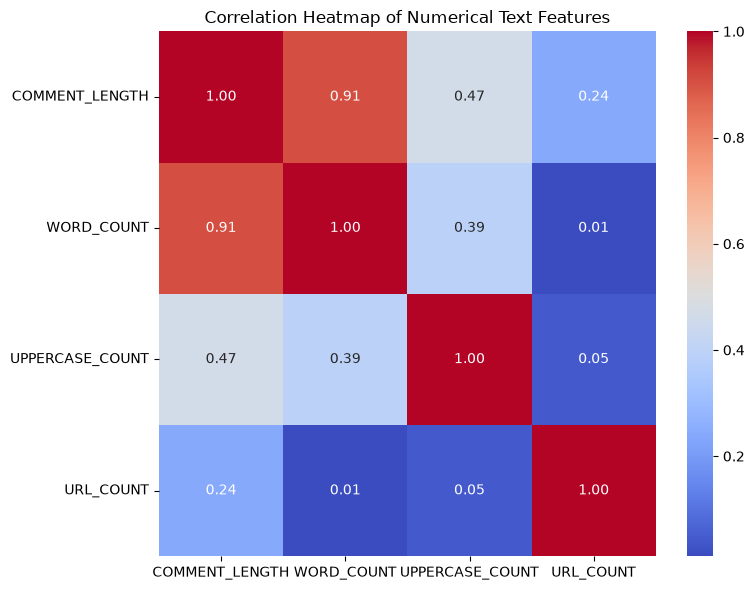

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_matrix = df[numerical_features].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Text Features")
plt.tight_layout()

plt.savefig("../output/figures/correlation_heatmap.png", dpi=300)

plt.show()

In [11]:
import re

def clean_text(text):
    if pd.isna(text):
        return ""

    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", "", text)
    text = re.sub(r"\d+", "", text)
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

df["cleaned_text"] = df["CONTENT"].apply(clean_text)

df[["CONTENT", "cleaned_text"]].head(10)

,CONTENT,cleaned_text
0,"Huh, anyway check out this you[tube] channel: ...",huh anyway check out this youtube channel koby...
1,Hey guys check out my new channel and our firs...,hey guys check out my new channel and our firs...
2,just for test I have to say murdev.com,just for test i have to say murdevcom
3,me shaking my sexy ass on my channel enjoy ^_^ ﻿,me shaking my sexy ass on my channel enjoy _
4,watch?v=vtaRGgvGtWQ Check this out .﻿,watchvvtarggvgtwq check this out
5,"Hey, check out my new website!! This site is a...",hey check out my new website this site is abou...
6,Subscribe to my channel ﻿,subscribe to my channel
7,i turned it on mute as soon is i came on i jus...,i turned it on mute as soon is i came on i jus...
8,You should check my channel for Funny VIDEOS!!﻿,you should check my channel for funny videos
9,and u should.d check my channel and tell me wh...,and u shouldd check my channel and tell me wha...


In [12]:
df["tokens"] = df["cleaned_text"].apply(lambda text: text.split())

df["TOKEN_COUNT"] = df["tokens"].apply(len)

print("Total tokens:", df["TOKEN_COUNT"].sum())
print("Average tokens per comment:", df["TOKEN_COUNT"].mean())
print("Maximum tokens in one comment:", df["TOKEN_COUNT"].max())
print("Minimum tokens in one comment:", df["TOKEN_COUNT"].min())

df[["cleaned_text", "tokens", "TOKEN_COUNT"]].head(10)

Total tokens: 28902
Average tokens per comment: 14.798771121351766
Maximum tokens in one comment: 208
Minimum tokens in one comment: 0


,cleaned_text,tokens,TOKEN_COUNT
0,huh anyway check out this youtube channel koby...,"[huh, anyway, check, out, this, youtube, chann...",8
1,hey guys check out my new channel and our firs...,"[hey, guys, check, out, my, new, channel, and,...",30
2,just for test i have to say murdevcom,"[just, for, test, i, have, to, say, murdevcom]",8
3,me shaking my sexy ass on my channel enjoy _,"[me, shaking, my, sexy, ass, on, my, channel, ...",10
4,watchvvtarggvgtwq check this out,"[watchvvtarggvgtwq, check, this, out]",4
5,hey check out my new website this site is abou...,"[hey, check, out, my, new, website, this, site...",14
6,subscribe to my channel,"[subscribe, to, my, channel]",4
7,i turned it on mute as soon is i came on i jus...,"[i, turned, it, on, mute, as, soon, is, i, cam...",18
8,you should check my channel for funny videos,"[you, should, check, my, channel, for, funny, ...",8
9,and u shouldd check my channel and tell me wha...,"[and, u, shouldd, check, my, channel, and, tel...",14


In [13]:
from collections import Counter

all_words = [word for tokens in df["tokens"] for word in tokens]

word_counts = Counter(all_words)

top_20_words = word_counts.most_common(20)

top_20_df = pd.DataFrame(top_20_words, columns=["Word", "Frequency"])

display(top_20_df)

,Word,Frequency
0,i,759
1,this,730
2,the,713
3,and,634
4,to,631
5,out,584
6,my,581
7,you,575
8,check,559
9,a,556


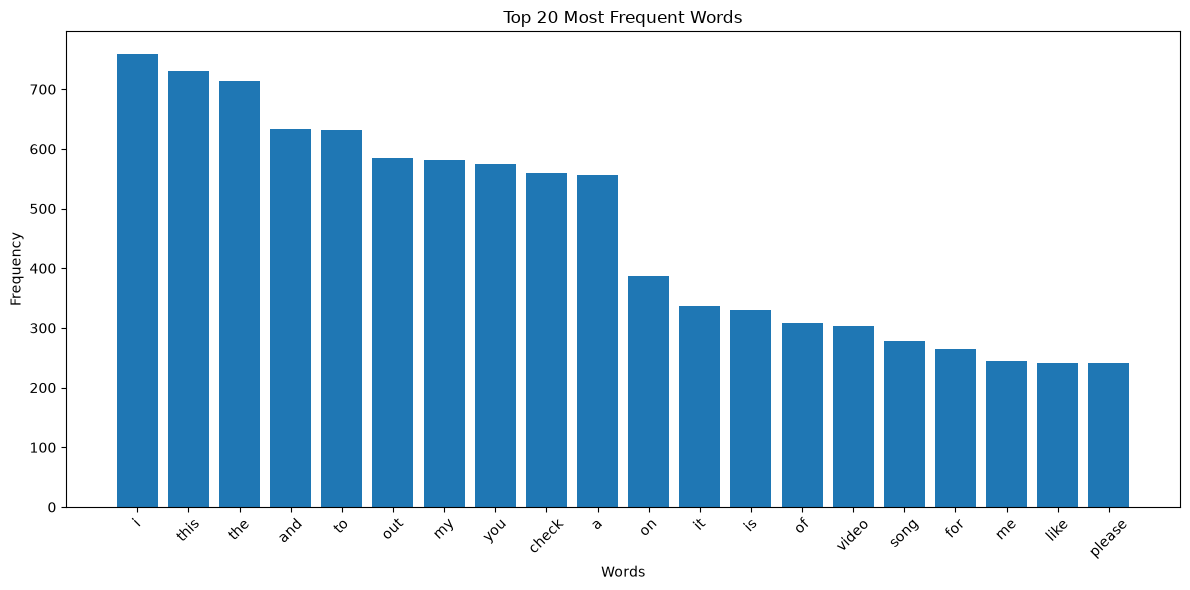

In [14]:
plt.figure(figsize=(12, 6))

plt.bar(top_20_df["Word"], top_20_df["Frequency"])

plt.title("Top 20 Most Frequent Words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("../output/figures/top_20_words.png", dpi=300)
plt.show()

In [15]:
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

filtered_words = [
    word for word in all_words
    if word not in stop_words
]

filtered_counts = Counter(filtered_words)

top_20_filtered = pd.DataFrame(
    filtered_counts.most_common(20),
    columns=["Word", "Frequency"]
)

display(top_20_filtered)

[nltk_data] Downloading package stopwords to /home/jovyan/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,Word,Frequency
0,check,559
1,video,304
2,song,278
3,like,242
4,please,242
5,subscribe,225
6,youtube,211
7,love,196
8,channel,192
9,im,167


In [16]:
df["CLASS_LABEL"] = df["CLASS"].map({0: "Ham", 1: "Spam"})

In [17]:
group_comparison = df.groupby("CLASS_LABEL").agg(
    COMMENT_COUNT=("CONTENT", "count"),
    AVG_COMMENT_LENGTH=("COMMENT_LENGTH", "mean"),
    AVG_WORD_COUNT=("WORD_COUNT", "mean")
)

display(group_comparison)

,COMMENT_COUNT,AVG_COMMENT_LENGTH,AVG_WORD_COUNT
CLASS_LABEL,,,
Ham,950,49.685263,9.108421
Spam,1003,137.496510,21.734796


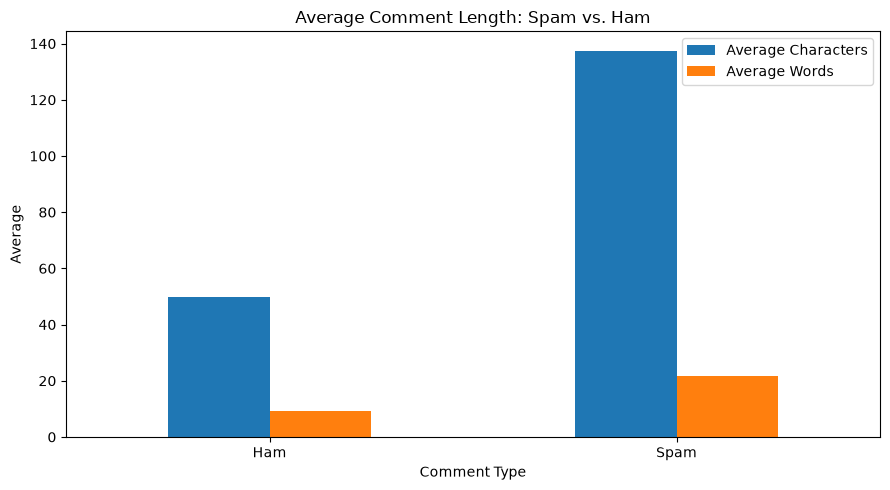

In [18]:
group_comparison[["AVG_COMMENT_LENGTH", "AVG_WORD_COUNT"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Comment Length: Spam vs. Ham")
plt.xlabel("Comment Type")
plt.ylabel("Average")
plt.xticks(rotation=0)
plt.legend(["Average Characters", "Average Words"])
plt.tight_layout()
plt.savefig("../output/figures/spam_ham_comparison.png", dpi=300)
plt.show()

In [19]:
display(group_comparison)

,COMMENT_COUNT,AVG_COMMENT_LENGTH,AVG_WORD_COUNT
CLASS_LABEL,,,
Ham,950,49.685263,9.108421
Spam,1003,137.496510,21.734796


In [20]:
##documentation of what happen above

In [25]:
from sklearn.model_selection import train_test_split

X = df["cleaned_text"]
y = df["CLASS"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y)
ts(normalize=True))

SyntaxError: unmatched ')' (370131643.py, line 12)

In [ ]:
print("DataFrame exists:", "df" in globals())
print("Columns:", df.columns.tolist())
print("Cleaned text exists:", "cleaned_text" in df.columns)
print("Class exists:", "CLASS" in df.columns)